Chuẩn bị dữ liệu

In [1]:
!pip install pyfim -q

print("Họ và tên: Trần Minh Tấn")
print("MSSV: 6451071071")

import pandas as pd
import time, warnings, requests
import matplotlib.pyplot as plt
from fim import apriori, fpgrowth

warnings.filterwarnings('ignore')

# Tải dữ liệu
file_id = '1UIeIAeGPrmXaSsFOtfhw9h5gK4RPkseI'
url = f'https://drive.google.com/uc?export=download&id={file_id}'
lines = requests.get(url).content.decode('utf-8').splitlines()
transactions = [[i.strip() for i in line.split(',') if i.strip()]
                for line in lines if line.strip()]
print(f"Số giao dịch: {len(transactions)}")

min_sups = [0.0001, 0.0003, 0.0005, 0.0008, 0.001]   # 0.01% -> 0.1%
MAX_LEN = 2   # bỏ giới hạn bằng cách đặt None (có thể rất nhiều tập ở 0.01%)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Họ và tên: Trần Minh Tấn
MSSV: 6451071071
Số giao dịch: 9835


Câu a: Apriori

In [2]:
print("Họ và tên: Trần Minh Tấn")
print("MSSV: 6451071071")

results_apriori = []
print("--- CÂU a: APRIORI ---")
for sup in min_sups:
    t0 = time.time()
    freq = apriori(transactions, target='s', supp=sup*100, zmin=1,
                   zmax=MAX_LEN if MAX_LEN else 0)
    t = time.time() - t0
    results_apriori.append({'min_sup': f"{sup*100:.2f}%",
                            'Số tập phổ biến': len(freq),
                            'Thời gian (s)': round(t, 4)})
    print(f"min_sup={sup*100:.2f}% | {len(freq)} tập | {t:.4f}s", flush=True)

df_apriori = pd.DataFrame(results_apriori)
display(df_apriori)

Họ và tên: Trần Minh Tấn
MSSV: 6451071071
--- CÂU a: APRIORI ---
min_sup=0.01% | 9805 tập | 0.0133s
min_sup=0.03% | 6412 tập | 0.0127s
min_sup=0.05% | 4946 tập | 0.0095s
min_sup=0.08% | 3699 tập | 0.0097s
min_sup=0.10% | 3138 tập | 0.0095s


,min_sup,Số tập phổ biến,Thời gian (s)
0,0.01%,9805,0.0133
1,0.03%,6412,0.0127
2,0.05%,4946,0.0095
3,0.08%,3699,0.0097
4,0.10%,3138,0.0095


Câu b: FP-Growth

In [3]:
print("Họ và tên: Trần Minh Tấn")
print("MSSV: 6451071071")

results_fpgrowth = []
print("--- CÂU b: FP-GROWTH ---")
for sup in min_sups:
    t0 = time.time()
    freq = fpgrowth(transactions, target='s', supp=sup*100, zmin=1,
                    zmax=MAX_LEN if MAX_LEN else 0)
    t = time.time() - t0
    results_fpgrowth.append({'min_sup': f"{sup*100:.2f}%",
                             'Số tập phổ biến': len(freq),
                             'Thời gian (s)': round(t, 4)})
    print(f"min_sup={sup*100:.2f}% | {len(freq)} tập | {t:.4f}s", flush=True)

df_fpgrowth = pd.DataFrame(results_fpgrowth)
display(df_fpgrowth)

Họ và tên: Trần Minh Tấn
MSSV: 6451071071
--- CÂU b: FP-GROWTH ---
min_sup=0.01% | 9805 tập | 0.0264s
min_sup=0.03% | 6412 tập | 0.0174s
min_sup=0.05% | 4946 tập | 0.0163s
min_sup=0.08% | 3699 tập | 0.0144s
min_sup=0.10% | 3138 tập | 0.0129s


,min_sup,Số tập phổ biến,Thời gian (s)
0,0.01%,9805,0.0264
1,0.03%,6412,0.0174
2,0.05%,4946,0.0163
3,0.08%,3699,0.0144
4,0.10%,3138,0.0129


Câu c: Biểu đồ so sánh

Họ và tên: Trần Minh Tấn
MSSV: 6451071071


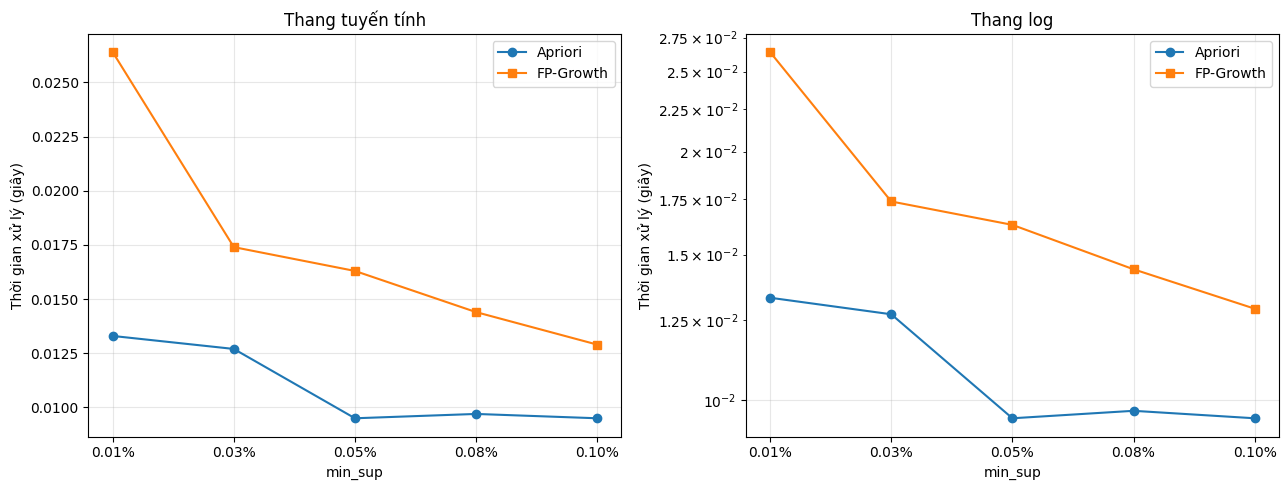

,min_sup,Số tập phổ biến,Apriori (s),FP-Growth (s)
0,0.01%,9805,0.0133,0.0264
1,0.03%,6412,0.0127,0.0174
2,0.05%,4946,0.0095,0.0163
3,0.08%,3699,0.0097,0.0144
4,0.10%,3138,0.0095,0.0129


Hai thuật toán cho cùng kết quả: True


In [4]:
print("Họ và tên: Trần Minh Tấn")
print("MSSV: 6451071071")

x = df_apriori['min_sup']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, scale in zip(axes, ['linear', 'log']):
    ax.plot(x, df_apriori['Thời gian (s)'], marker='o', label='Apriori')
    ax.plot(x, df_fpgrowth['Thời gian (s)'], marker='s', label='FP-Growth')
    ax.set_yscale(scale)
    ax.set_title('Thang tuyến tính' if scale == 'linear' else 'Thang log')
    ax.set_xlabel('min_sup')
    ax.set_ylabel('Thời gian xử lý (giây)')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

df_compare = pd.DataFrame({
    'min_sup': x,
    'Số tập phổ biến': df_apriori['Số tập phổ biến'],
    'Apriori (s)': df_apriori['Thời gian (s)'],
    'FP-Growth (s)': df_fpgrowth['Thời gian (s)'],
})
display(df_compare)
print("Hai thuật toán cho cùng kết quả:",
      (df_apriori['Số tập phổ biến'] == df_fpgrowth['Số tập phổ biến']).all())